In [126]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import warnings as Ignore

In [127]:
df_uribarri = pd.read_excel("data/datos.xlsx")
df_uribarri.head()

,Año,Habitantes,Actividad económica,Extranjera (%),Renta neta media,Edad media,Menores (%),Mayores 65 (%),Intervenciones
0,2014,36595,1767,9.6,12807.622718,47.9,13.0,27.8,23
1,2015,36501,1824,10.0,13831.000000,47.9,13.0,27.3,54
2,2016,36294,1831,10.2,14188.000000,48.0,13.0,27.7,109
3,2017,36080,1808,10.4,14414.000000,48.1,13.0,27.7,169
4,2018,36191,1817,10.5,14850.000000,48.1,13.0,27.5,119


In [128]:
#Añadimos los valores que nos hemos predecido con las regresion lineales simples.
nuevosvalores = pd.DataFrame({
    'Año': [2024, 2025, 2026],
    'Extranjera (%)': [11.045792079207928, 11.16683168316834, 11.287871287128723],         
    'Renta neta media': [16871.41432530689, 17245.90862169396, 17620.402918080916],
    'Edad media': [48.48811881188119, 48.547524752475255, 48.606930693069316]})

#Concatenamos para unir los dos dataframes
df_final = pd.concat([df_uribarri, nuevosvalores], ignore_index=True)

df_final

,Año,Habitantes,Actividad económica,Extranjera (%),Renta neta media,Edad media,Menores (%),Mayores 65 (%),Intervenciones
0,2014,36595.0,1767.0,9.600000,12807.622718,47.900000,13.0,27.8,23.0
1,2015,36501.0,1824.0,10.000000,13831.000000,47.900000,13.0,27.3,54.0
2,2016,36294.0,1831.0,10.200000,14188.000000,48.000000,13.0,27.7,109.0
3,2017,36080.0,1808.0,10.400000,14414.000000,48.100000,13.0,27.7,169.0
4,2018,36191.0,1817.0,10.500000,14850.000000,48.100000,13.0,27.5,119.0
5,2019,36147.0,1779.0,10.500000,15340.000000,48.100000,13.0,27.7,129.0
6,2020,36414.0,2027.0,10.400000,14956.000000,48.200000,13.0,27.8,136.0
7,2021,36111.0,1998.0,10.500000,15659.000000,48.400000,12.4,27.6,117.0
8,2022,35990.0,1977.0,11.200000,16615.000000,48.300000,12.4,27.6,148.0
9,2023,36025.0,1976.0,11.000000,16620.000000,48.400000,12.0,28.0,74.0


In [129]:
#Eliminamos las columnas innecesarias
df = df_final.drop(columns=["Habitantes", "Actividad económica", "Menores (%)", "Mayores 65 (%)"])
df

,Año,Extranjera (%),Renta neta media,Edad media,Intervenciones
0,2014,9.600000,12807.622718,47.900000,23.0
1,2015,10.000000,13831.000000,47.900000,54.0
2,2016,10.200000,14188.000000,48.000000,109.0
3,2017,10.400000,14414.000000,48.100000,169.0
4,2018,10.500000,14850.000000,48.100000,119.0
5,2019,10.500000,15340.000000,48.100000,129.0
6,2020,10.400000,14956.000000,48.200000,136.0
7,2021,10.500000,15659.000000,48.400000,117.0
8,2022,11.200000,16615.000000,48.300000,148.0
9,2023,11.000000,16620.000000,48.400000,74.0


In [130]:
# Entrenamos con los datos conocidos y quitamos los NAN (hemos tenido que poner los años 2024,2025,2026 porque sino daba mal)
train_df = df.dropna(subset=["Intervenciones"])

X = train_df[["Extranjera (%)", "Renta neta media", "Edad media"]]
y = train_df["Intervenciones"]

In [131]:
#Separamos en train y test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

In [132]:
#Entrenamos el modelo
model = LinearRegression()
model.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [133]:
# Predecimos el modelo
y_pred_train = model.predict(X_train)
y_pred_test = model.predict(X_test)

# Rellenamos las intervenciones con lo que nos ha dado
años_futuros = df[df["Intervenciones"].isna()][["Extranjera (%)", "Renta neta media", "Edad media"]]
predicciones_futuras = model.predict(años_futuros)

# Mostramos resultados
print("Predicciones futuras de intervenciones:")
print("2024:", int(predicciones_futuras[0]))
print("2025:", int(predicciones_futuras[1]))
print("2026:", int(predicciones_futuras[2]))

Predicciones futuras de intervenciones:
2024: 125
2025: 129
2026: 132


In [134]:
#Calculamos metricas de error
print("MSE (train):", mean_squared_error(y_train, y_pred_train))
print("MAE (train):", mean_absolute_error(y_train, y_pred_train))
print("R² (train):", r2_score(y_train, y_pred_train))


MSE (train): 729.7715213495214
MAE (train): 22.81540200657816
R² (train): 0.6093726972741851


In [135]:
#Calculamos los coeficientes
print(model.coef_)
print(model.intercept_)

[ 4.67187339e+02 -2.30878950e-01  5.61154545e+02]
-28348.752598017916


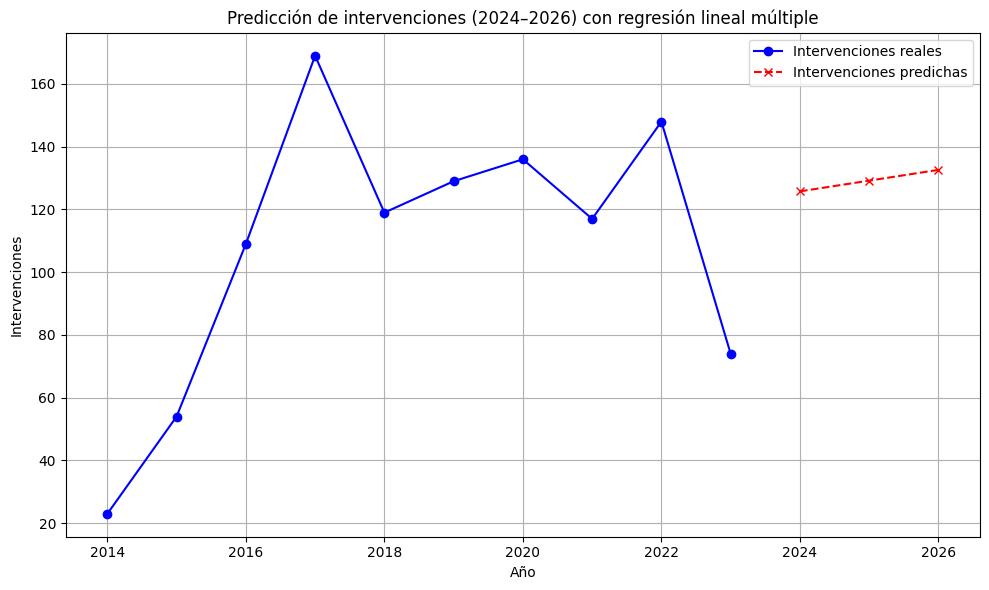

In [136]:
#Graficamos la regresión para que se vea mejor el resultado
df_reales = df.dropna(subset=["Intervenciones"])
df_predichas = df[df["Intervenciones"].isna()].copy()
df_predichas["Intervenciones"] = predicciones_futuras

plt.figure(figsize=(10, 6))
plt.plot(df_reales["Año"], df_reales["Intervenciones"], marker="o", label="Intervenciones reales", color="blue")
plt.plot(df_predichas["Año"], df_predichas["Intervenciones"], marker="x", linestyle="--", label="Intervenciones predichas", color="red")
plt.xlabel("Año")
plt.ylabel("Intervenciones")
plt.title("Predicción de intervenciones (2024–2026) con regresión lineal múltiple")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
